# Regular experiments: layered vs. looped transformers

In [1]:
# Figure 2 depth/loop experiment (baseline and shared-weight looped transformer)

import torch
from matplotlib import pyplot as plt
import os
import numpy as np

from linear_transformer import generate_data, DataMode
from experiments_helper import (
    build_transformer,
    step,
    run_experiment_suite,
    compute_loss_dict,
    compute_looped_loss_by_loop_count,
    compute_dist_identity,
    compute_dist_dict,
    compute_data_condition_numbers,
    plot_loss_curves,
    plot_parameter_matrices,
    plot_dist_to_identity,
    plot_loop_loss_curves,
)

np.set_printoptions(precision=2, suppress=True)
torch.set_printoptions(precision=2)

log_dir = 'log'
cur_dir = log_dir
os.makedirs(cur_dir, exist_ok=True)

In [2]:
# Problem parameters (defined in experiments_helper.py; edit them there so the
# helper functions see the same values)

from experiments_helper import (
    device, lr, clip_r, alg, normal_data_mode, N, d, n_head, B, var,
    max_iters, hist_stride, stride, TEST_SEED,
)

print(f'Running on device: {device}.')

Running on device: cuda.


In [3]:
####################################
# Train layered and shared-weight looped transformers
####################################

filename_format = '/figure_two_layers_vs_loops_{}_{}.pth'
filename = cur_dir + filename_format.format(N, d)

In [ ]:
seeds = [0, 1, 2]
n_layers_loops = [1, 2, 5, 10]
model_types = ['layered', 'looped']

hist_dict = run_experiment_suite(seeds, n_layers_loops, model_types, filename, freeze_p=True)  # [P-FIX] paper's P = [[0, 0], [0, 1]]

Run 1/8: seed=0, count=1, type=layered, N=10, mode=DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), heads=1, attention=linear, freeze_p=True
iter 0 | Loss: 5.583387851715088 | time: 0.00561070442199707 | gradnorm: 4.943443298339844
iter 1 | Loss: 5.09586238861084 | time: 0.004842996597290039 | gradnorm: 4.565327167510986
iter 2 | Loss: 5.328909873962402 | time: 0.00482940673828125 | gradnorm: 4.799430847167969
iter 3 | Loss: 5.160664081573486 | time: 0.004583120346069336 | gradnorm: 4.6755194664001465
iter 4 | Loss: 5.127560138702393 | time: 0.0027451515197753906 | gradnorm: 4.502877712249756
iter 100 | Loss: 4.155155658721924 | time: 0.0025293827056884766 | gradnorm: 3.831400156021118
iter 200 | Loss: 3.590285062789917 | time: 0.0025446414947509766 | gradnorm: 3.3312251567840576
iter 300 | Loss: 2.9695944786071777 | time: 0.0025420188903808594 | gradnorm: 2.7237231731414795
iter 400 | Loss: 2.45053768157959 | time: 0.0026597976684570312 | gradnorm: 

In [11]:
loss_dict = compute_loss_dict(hist_dict, test_seed=TEST_SEED)

(0, 1, 'layered', 10, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1)
Testing model: seed=0, count=1, type=layered, N=10, train data=DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), heads=1, attention=linear
(0, 1, 'looped', 10, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1)
Testing model: seed=0, count=1, type=looped, N=10, train data=DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), heads=1, attention=linear
(0, 2, 'layered', 10, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1)
Testing model: seed=0, count=2, type=layered, N=10, train data=DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), heads=1, attention=linear
(0, 2, 'looped', 10, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1)
Testing model: seed=0, count=2, type=loop

In [12]:
####################################
# integrated test-loss comparison: layered vs shared-weight looped
####################################

fig_dir = 'figures'
os.makedirs(fig_dir, exist_ok=True)
iterations = np.arange(0, max_iters, stride)

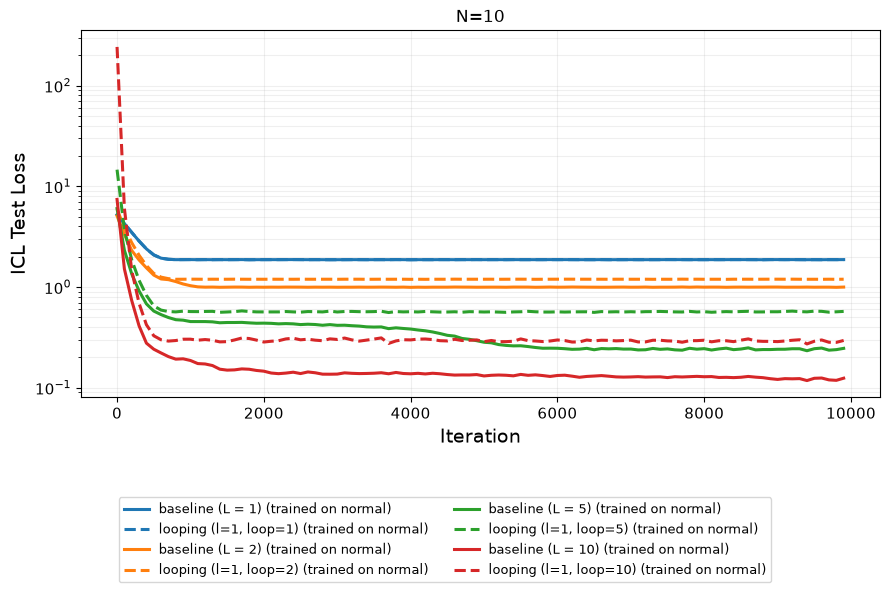

In [13]:
plot_loss_curves(loss_dict, n_layers_loops, ['layered', 'looped'], iterations, fig_dir=fig_dir)

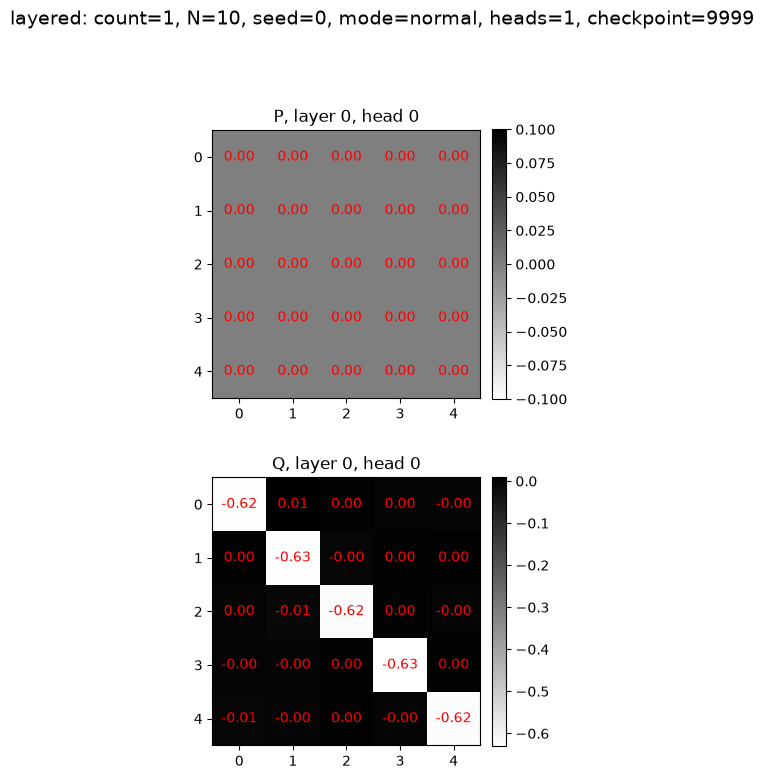

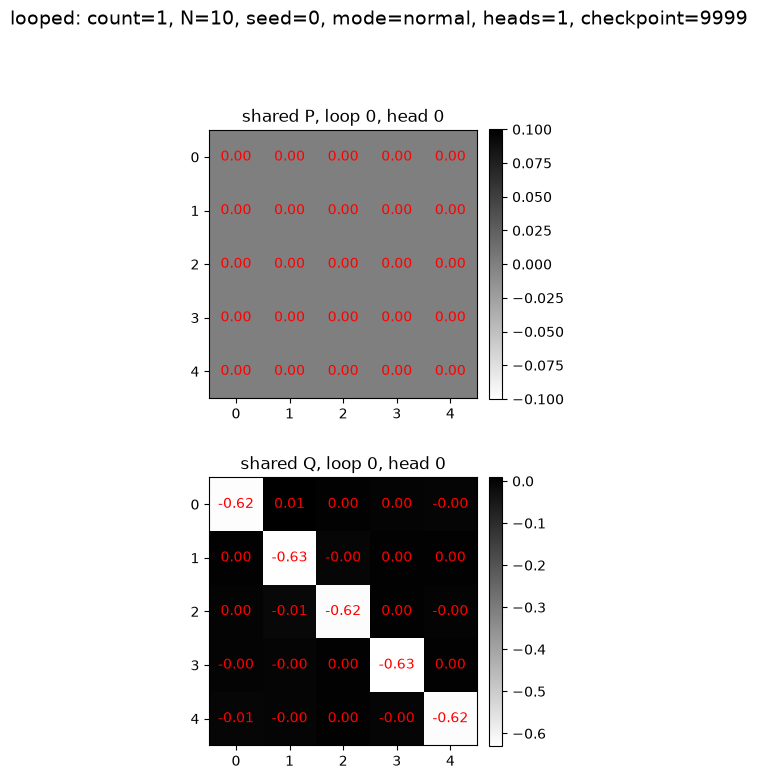

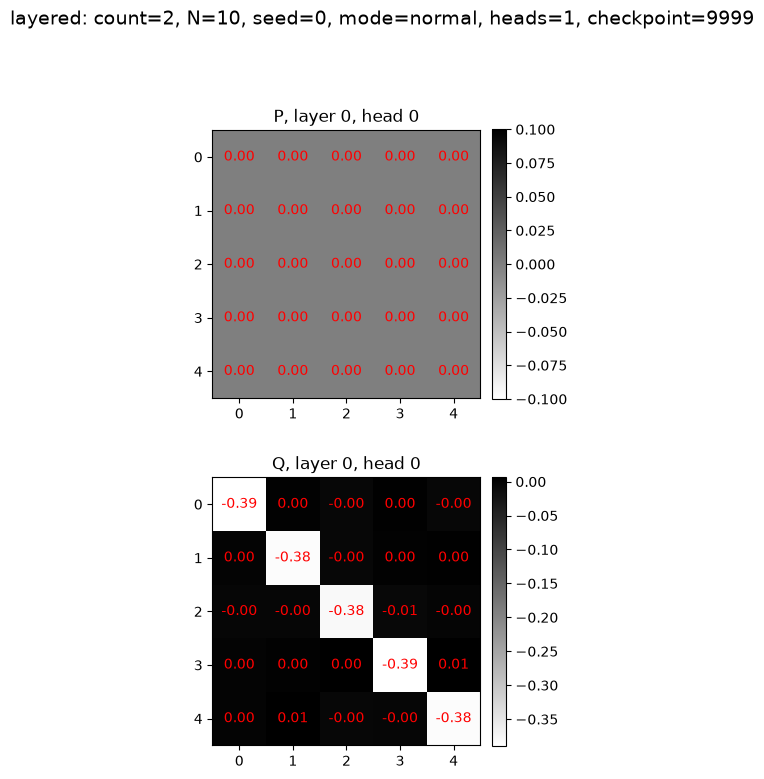

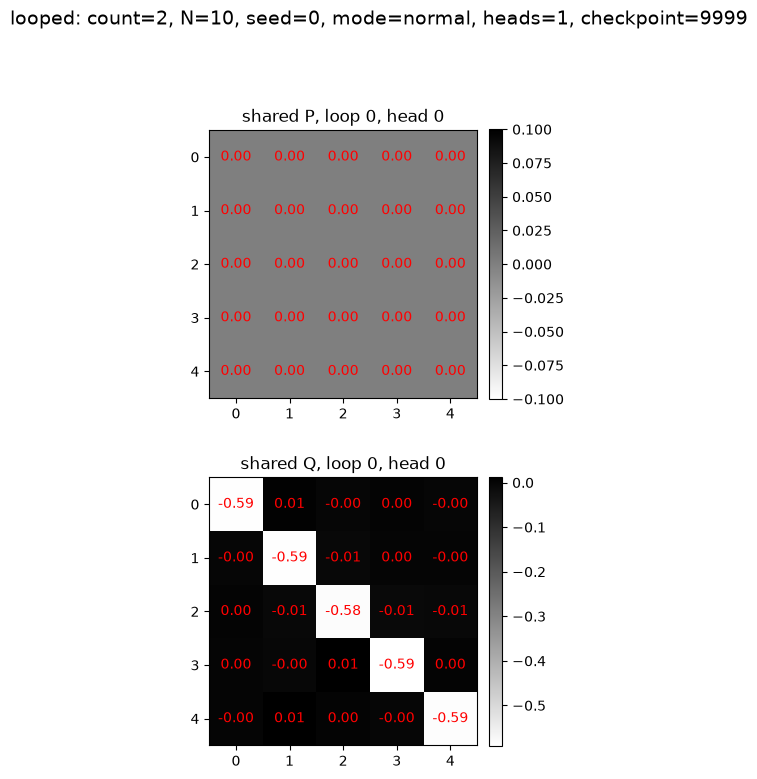

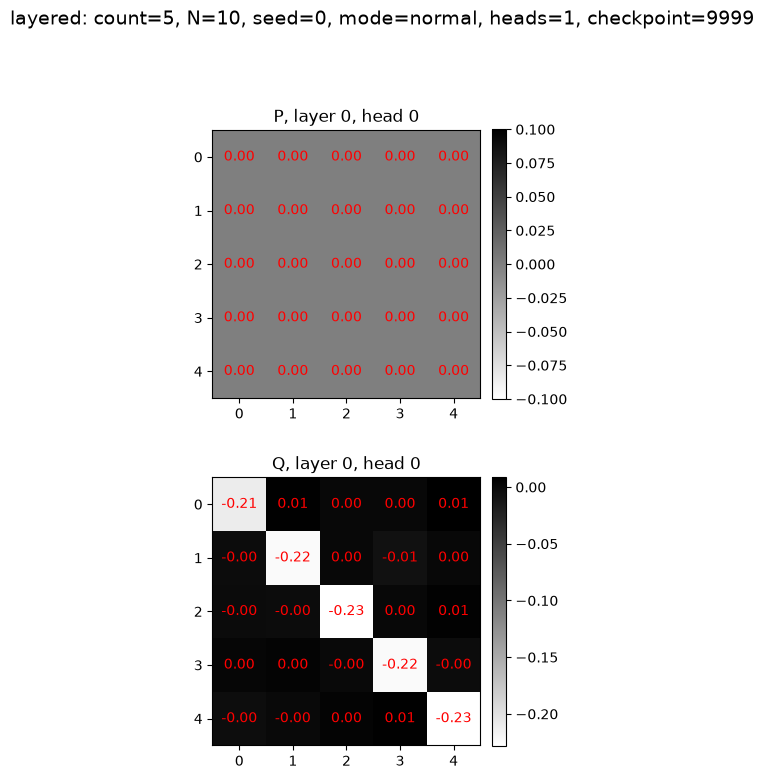

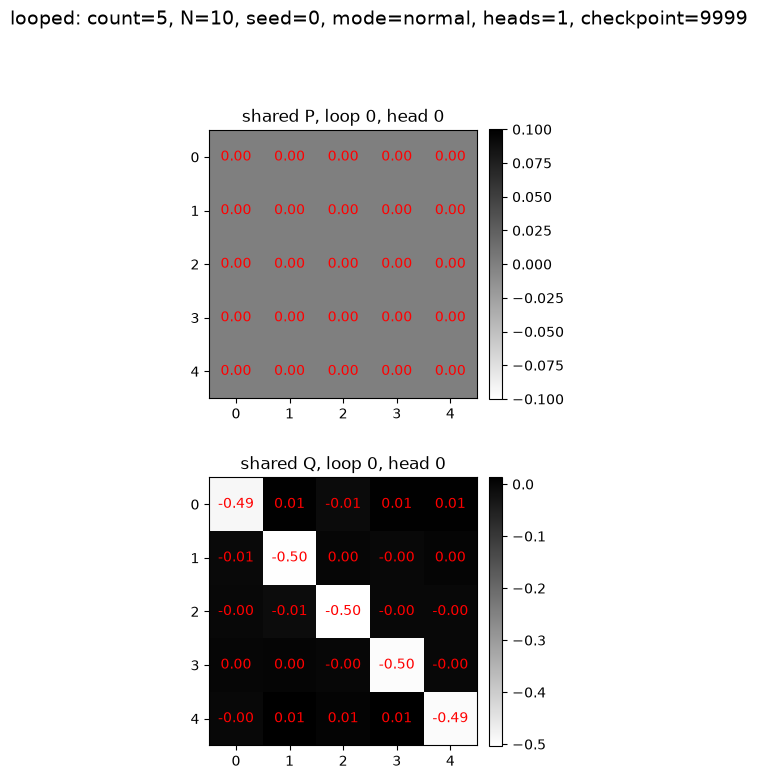

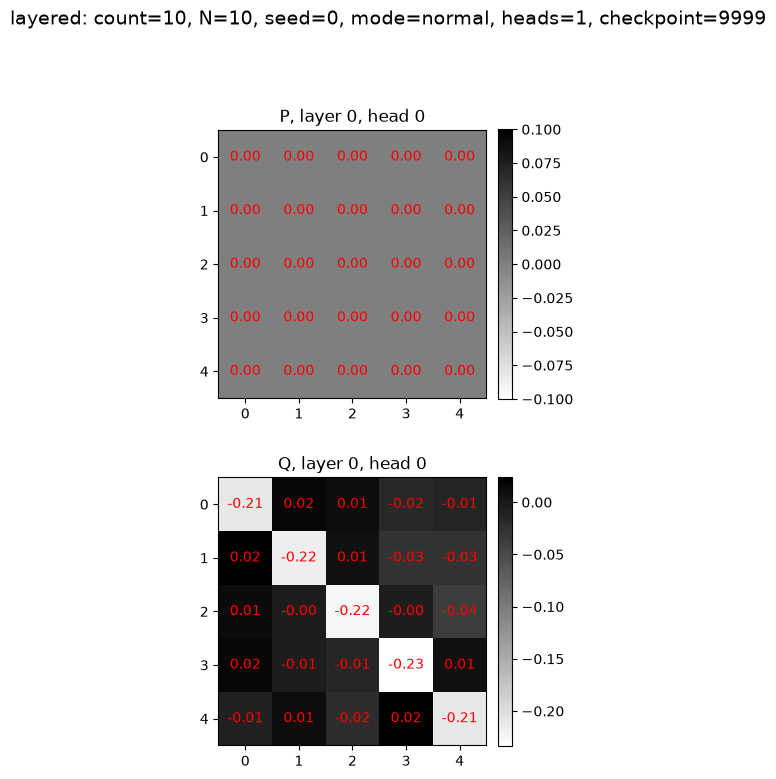

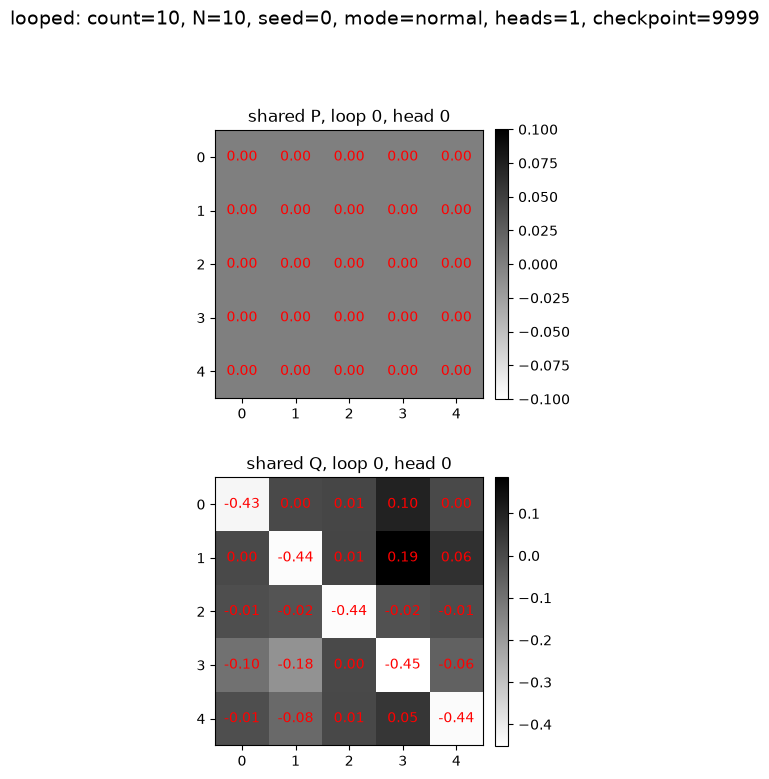

In [14]:
plot_parameter_matrices(hist_dict, seeds[0], n_layers_loops, model_types, n_head,
                        hist_stride=hist_stride, fig_dir=fig_dir)

In [15]:
iterations = np.arange(0, max_iters, stride)
dist_dict = compute_dist_dict(hist_dict, iterations, n_head, hist_stride=hist_stride)

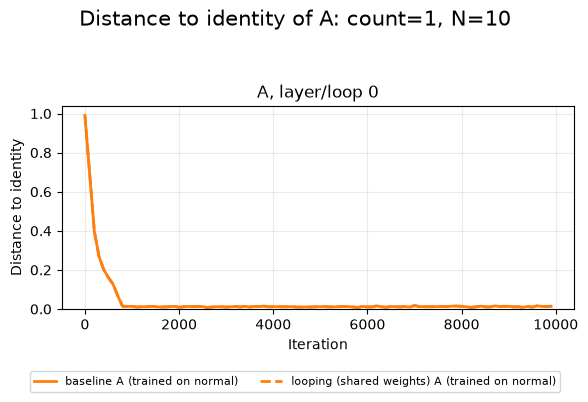

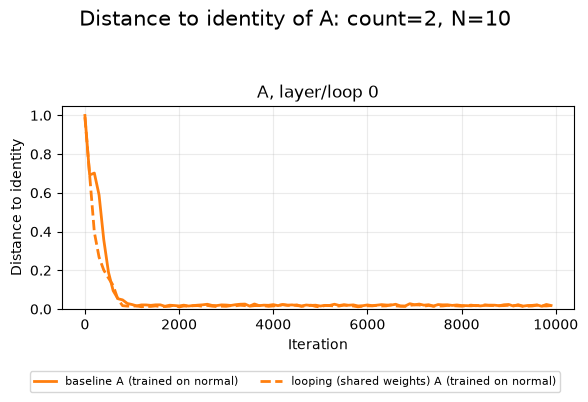

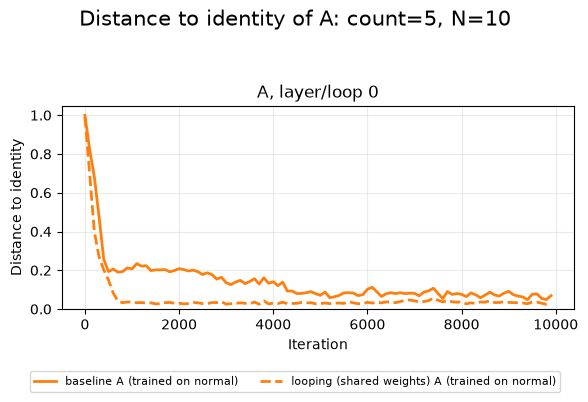

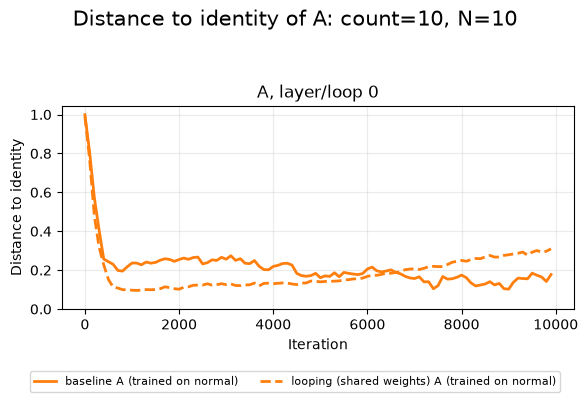

In [16]:
plot_dist_to_identity(dist_dict, n_layers_loops, iterations, fig_dir=fig_dir)